# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
from aitlas.datasets import Sen1Floods11Dataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose

## Visualize images and masks

Sentinel-2 images and hand labeled annotations

Total number of patches: 446


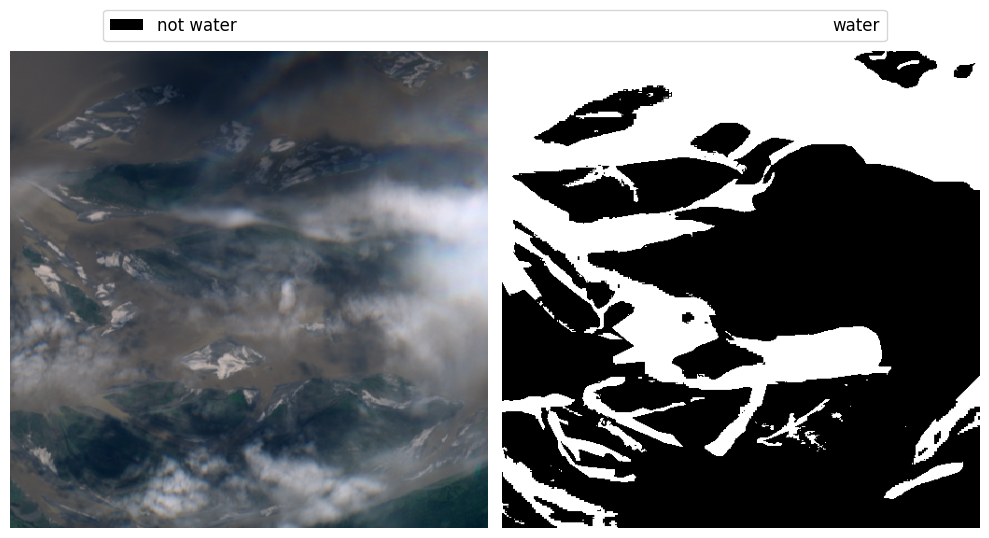

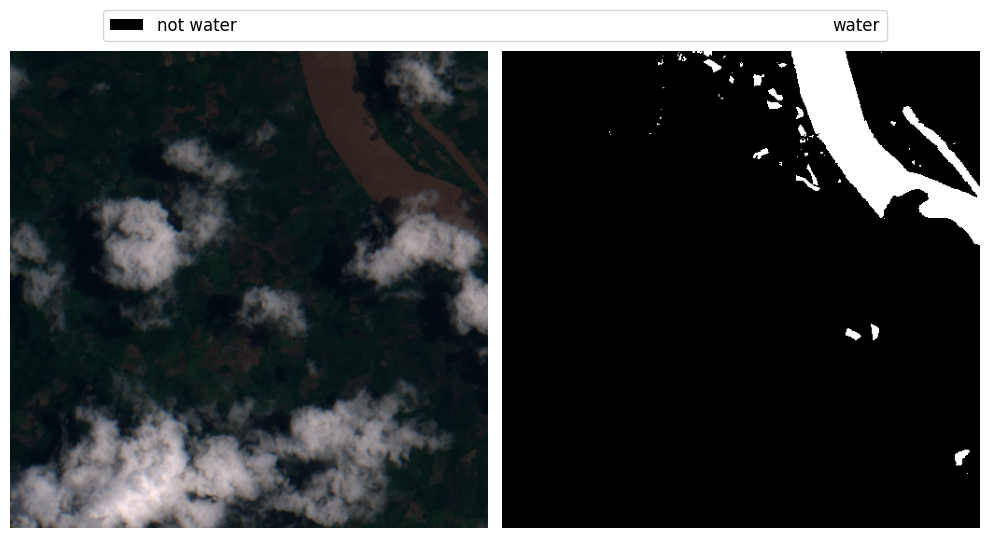

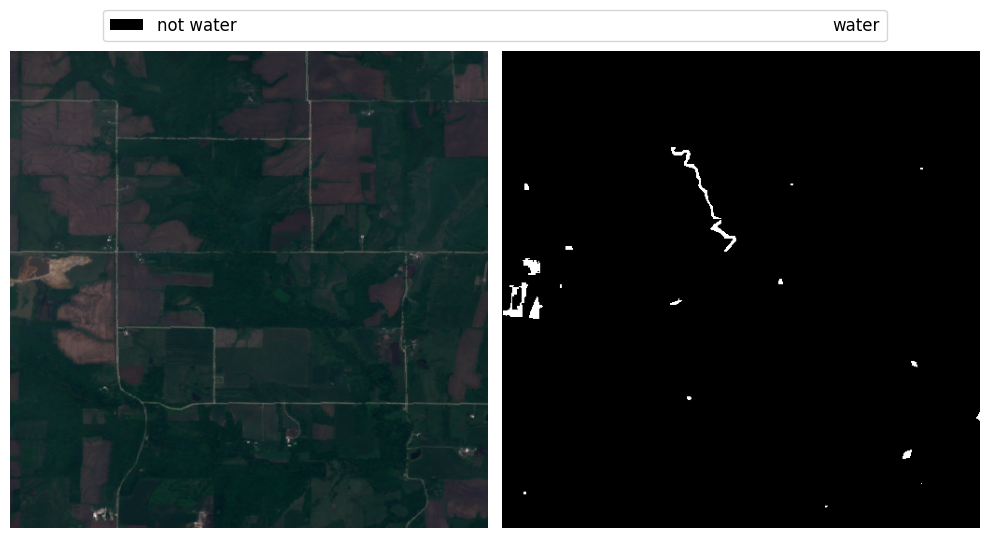

In [35]:
dataset_config = {
    "source_dir": "/home/dragik/data/FAIR_EO/sen1floods11/v1.1/data/flood_events/HandLabeled/S2Hand/",
    "annot_dir": "/home/dragik/data/FAIR_EO/sen1floods11/v1.1/data/flood_events/HandLabeled/LabelHand/",
    "imagery": "S2",
    "annotations": "hand labeled"
}
dataset = Sen1Floods11Dataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(2);
dataset.show_image(50);
dataset.show_image(400);

Sentinel-2 images and weakly labeled annotations

Total number of patches: 4384


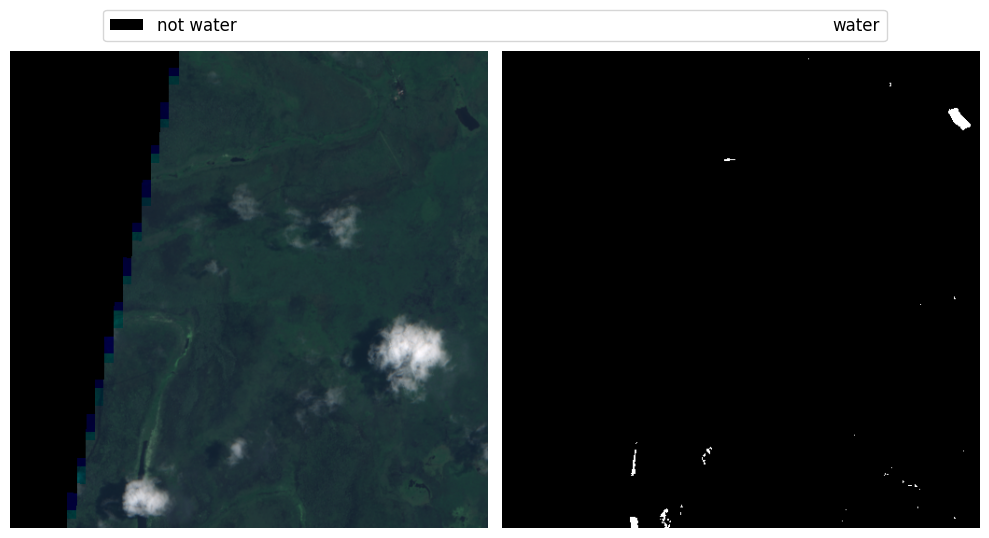

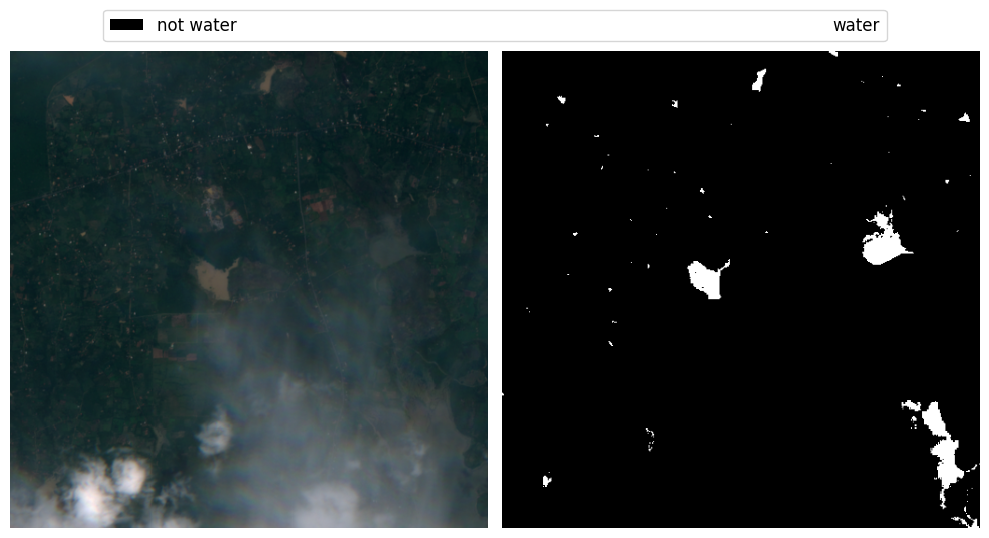

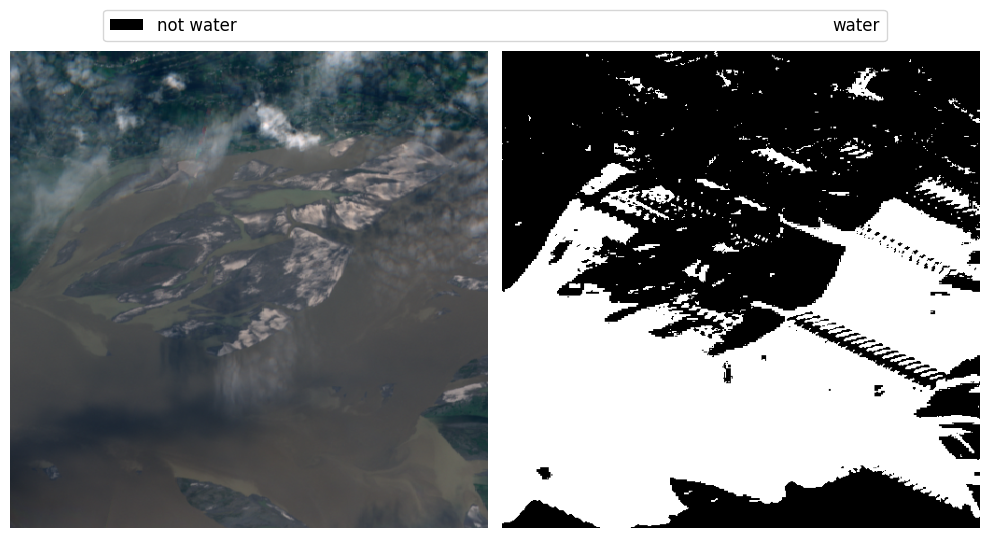

In [36]:
dataset_config = {
    "source_dir": "/home/dragik/data/FAIR_EO/sen1floods11/v1.1/data/flood_events/WeaklyLabeled/S2Weak/",
    "annot_dir": "/home/dragik/data/FAIR_EO/sen1floods11/v1.1/data/flood_events/WeaklyLabeled/S2IndexLabelWeak/",
    "imagery": "S2",
    "annotations": "weakly labeled"
}
dataset = Sen1Floods11Dataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(2);
dataset.show_image(50);
dataset.show_image(400);

Sentinel-1 images and hand labeled annotations

Total number of patches: 446


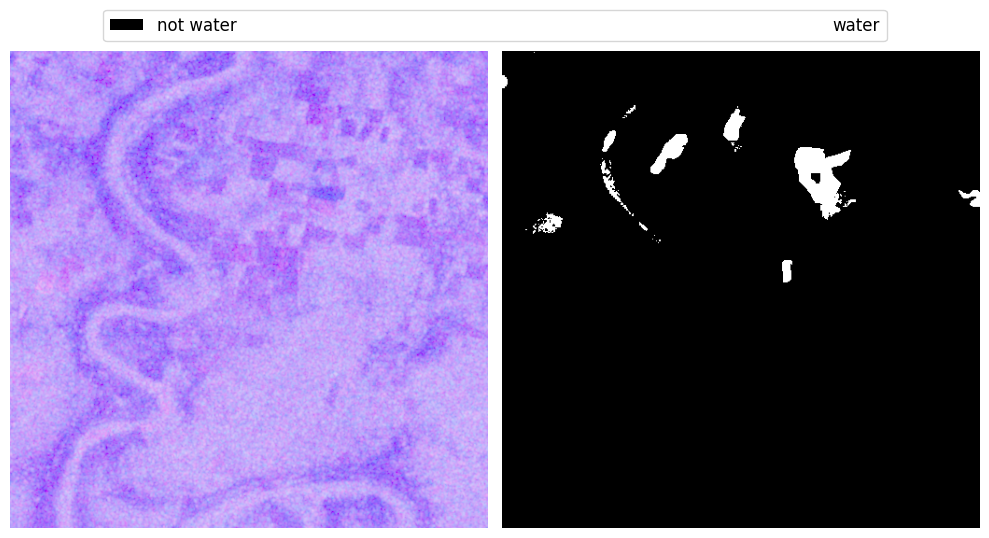

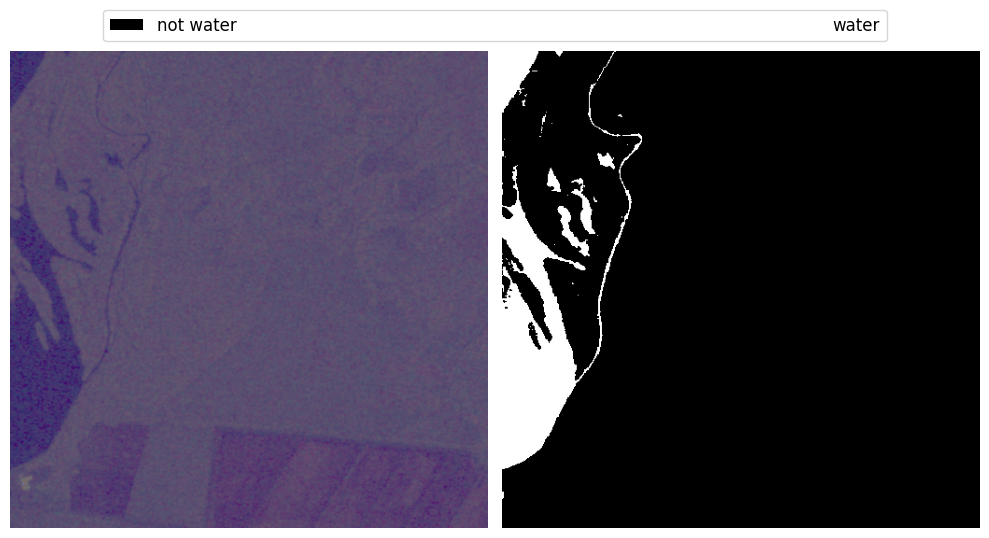

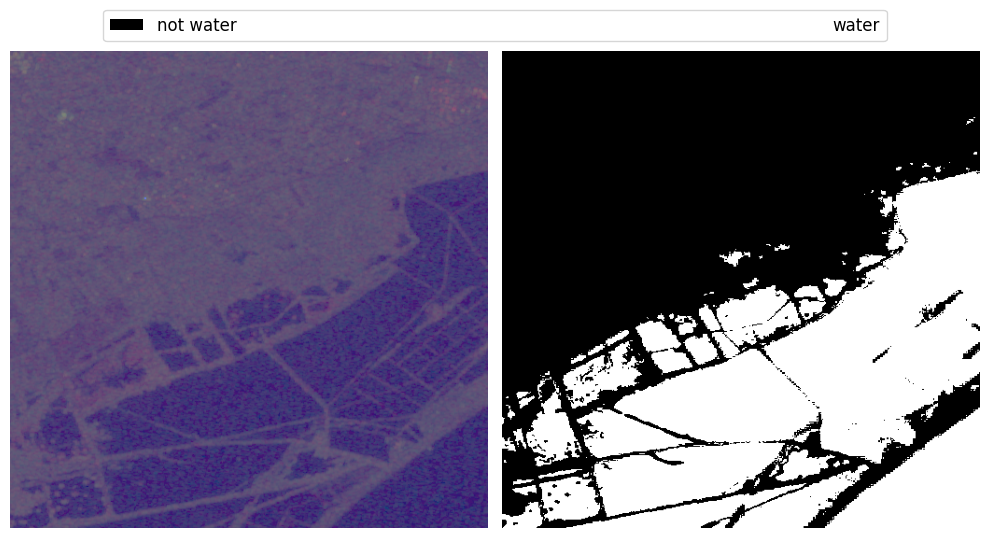

In [43]:
dataset_config = {
    "source_dir": "/home/dragik/data/FAIR_EO/sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/",
    "annot_dir": "/home/dragik/data/FAIR_EO/sen1floods11/v1.1/data/flood_events/HandLabeled/LabelHand/",
    "imagery": "S1",
    "annotations": "hand labeled"
}
dataset = Sen1Floods11Dataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(2);
dataset.show_image(50);
dataset.show_image(400);

Sentinel-1 images and weakly labeled annotations

Total number of patches: 4384


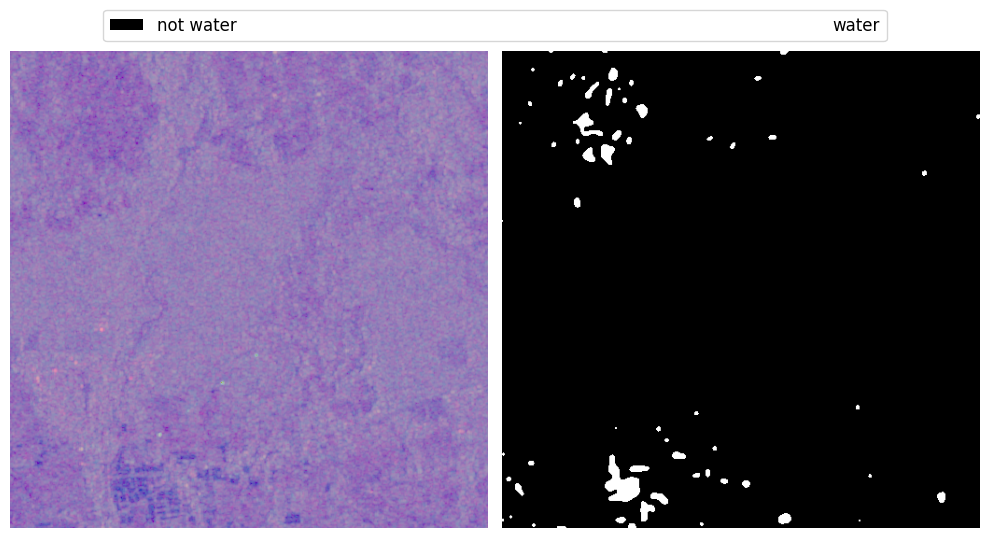

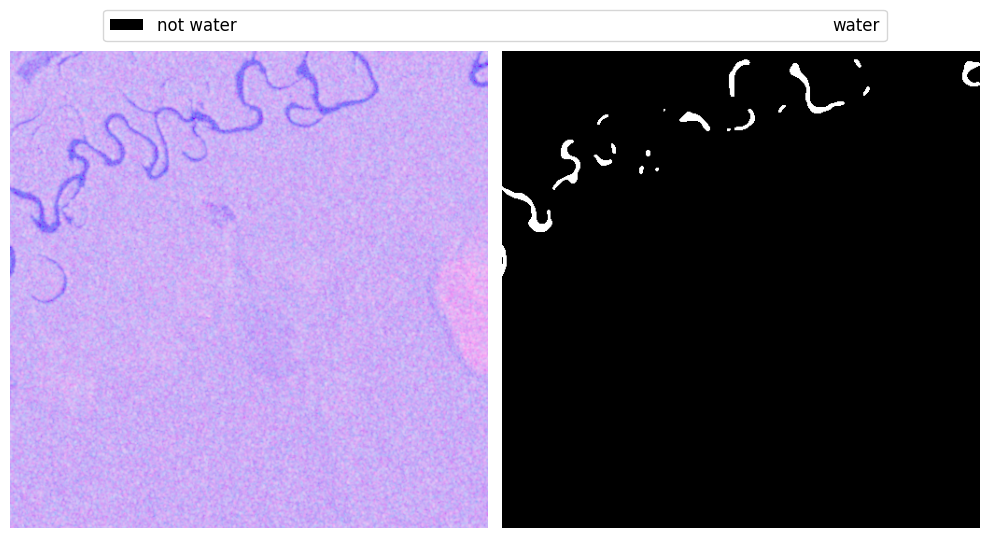

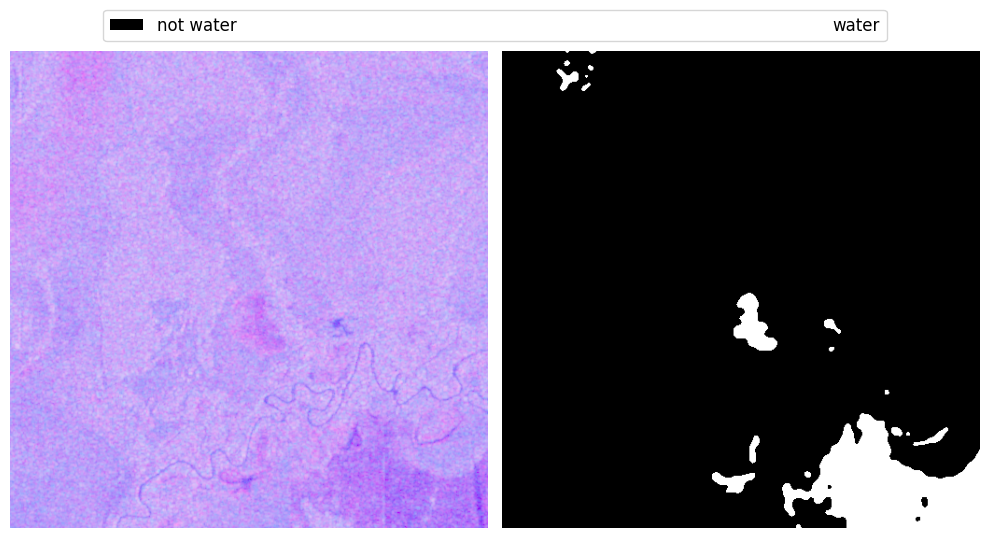

In [53]:
dataset_config = {
    "source_dir": "/home/dragik/data/FAIR_EO/sen1floods11/v1.1/data/flood_events/WeaklyLabeled/S1Weak/",
    "annot_dir": "/home/dragik/data/FAIR_EO/sen1floods11/v1.1/data/flood_events/WeaklyLabeled/S1OtsuLabelWeak/",
    "imagery": "S1",
    "annotations": "weakly labeled"
}
dataset = Sen1Floods11Dataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(2);
dataset.show_image(50);
dataset.show_image(400);

In [49]:
dataset.data_distribution_table()

,Number of pixels
not water,957374369.0
water,190719211.0


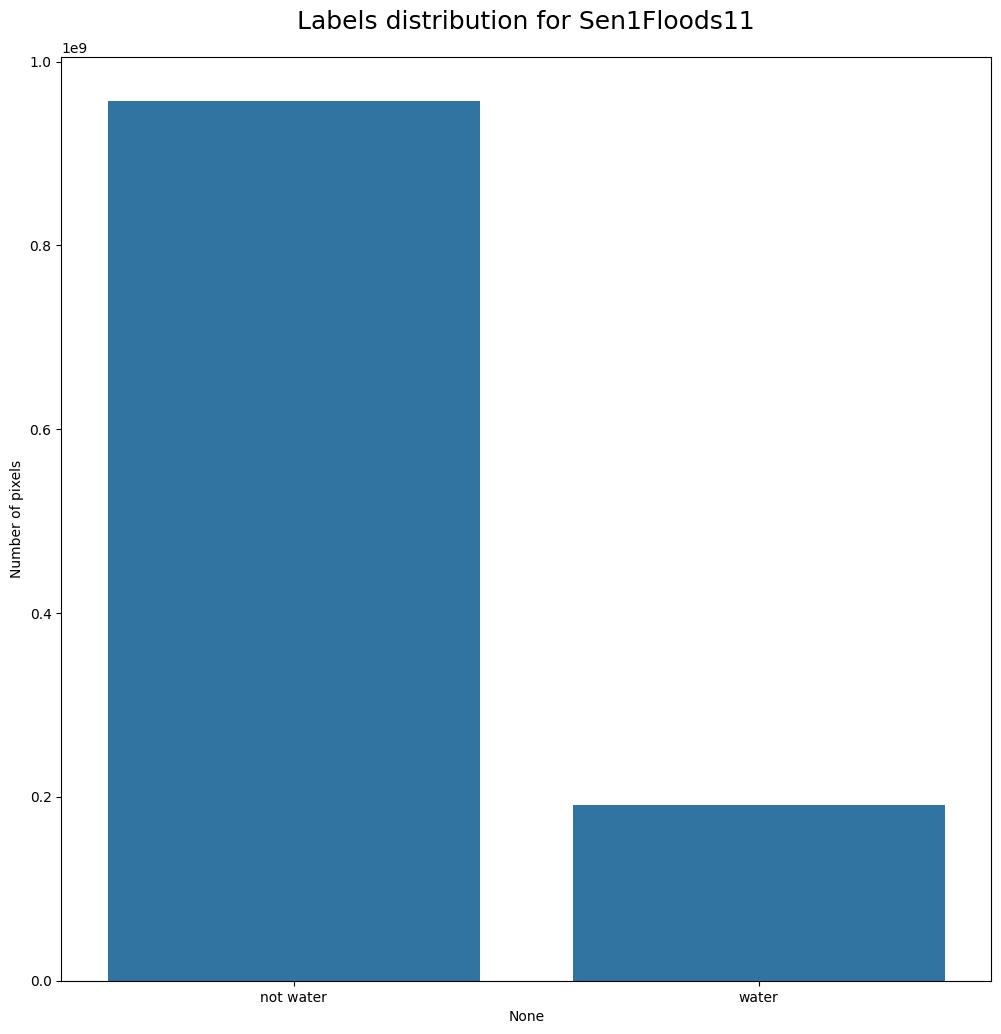

In [50]:
dataset.data_distribution_barchart();

## Load training data

In [74]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "source_dir": "/home/dragik/data/FAIR_EO/sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/",
    "annot_dir": "/home/dragik/data/FAIR_EO/sen1floods11/v1.1/data/flood_events/HandLabeled/LabelHand/",
    "imagery": "S1",
    "annotations": "hand labeled",
    "csv_file": "/home/dragik/data/FAIR_EO/sen1floods11/v1.1/splits/flood_handlabeled/flood_train_data.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = Sen1Floods11Dataset(train_dataset_config)
len(train_dataset)

252

## Create the model

In [75]:
epochs = 50
model_directory = "/home/dragik/data/FAIR_EO/experiments/sen1floods11"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [76]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2026-04-20 10:03:33,511 INFO Starting training.
training: 100%|██████████| 16/16 [00:03<00:00,  5.20it/s]
2026-04-20 10:03:36,633 INFO epoch: 1, time: 3, loss:  0.49642
testing on train set: 100%|██████████| 16/16 [00:01<00:00, 10.42it/s]
2026-04-20 10:03:39,998 INFO IOU:0.03237348459240125, IOU mean:0.03141361830415578, IOU per Class:[0.00257592 0.06025132]
training: 100%|██████████| 16/16 [00:03<00:00,  5.08it/s]
2026-04-20 10:03:43,153 INFO epoch: 2, time: 4, loss:  0.43696
testing on train set: 100%|██████████| 16/16 [00:01<00:00,  9.69it/s]
2026-04-20 10:03:44,821 INFO IOU:0.03378994856848842, IOU mean:0.029824134776619167, IOU per Class:[0.         0.05964827]
training: 100%|██████████| 16/16 [00:03<00:00,  4.98it/s]
2026-04-20 10:03:48,038 INFO epoch: 3, time: 4, loss:  0.40967
testing on train set: 100%|██████████| 16/16 [00:01<00:00,  9.93it/s]
2026-04-20 10:03:49,667 INFO IOU:0.03419567388960403, IOU mean:0.02989456011229729, IOU per Class:[0.         0.05978912]
training: 10

## Evaluate the model

In [77]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "source_dir": "/home/dragik/data/FAIR_EO/sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/",
    "annot_dir": "/home/dragik/data/FAIR_EO/sen1floods11/v1.1/data/flood_events/HandLabeled/LabelHand/",
    "imagery": "S1",
    "annotations": "hand labeled",
    "csv_file": "/home/dragik/data/FAIR_EO/sen1floods11/v1.1/splits/flood_handlabeled/flood_valid_data.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = Sen1Floods11Dataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/experiments/sen1floods11/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

89


2026-04-20 10:09:10,373 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/sen1floods11/checkpoint.pth.tar
2026-04-20 10:09:10,722 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/sen1floods11/checkpoint.pth.tar at epoch 51
testing on test set: 100%|██████████| 23/23 [00:00<00:00, 25.17it/s]


[{'IOU': 0.689651451765566,
  'IOU mean': 0.37039047412658005,
  'IOU per Class': array([0.74078095, 0.        ])}]

## Predictions

2026-04-20 10:09:57,377 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/sen1floods11/checkpoint.pth.tar
2026-04-20 10:09:57,690 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/sen1floods11/checkpoint.pth.tar at epoch 51


90


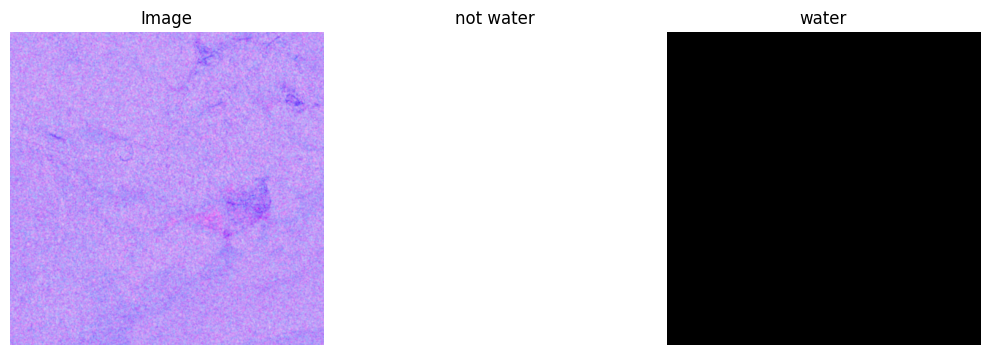

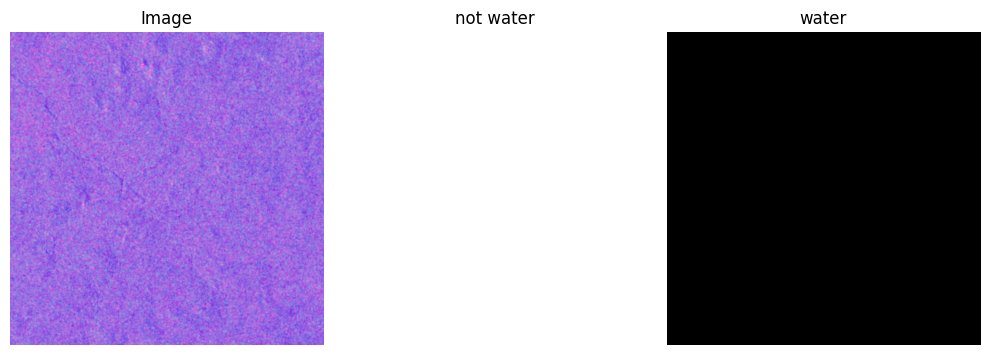

In [79]:
model_path = "/home/dragik/data/FAIR_EO/experiments/sen1floods11/checkpoint.pth.tar"
labels = ["not water","water"]
transform = MinMaxNormTranspose()
model.load_model(model_path)

test_dataset_config = {
    "source_dir": "/home/dragik/data/FAIR_EO/sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/",
    "annot_dir": "/home/dragik/data/FAIR_EO/sen1floods11/v1.1/data/flood_events/HandLabeled/LabelHand/",
    "imagery": "S1",
    "annotations": "hand labeled",
    "csv_file": "/home/dragik/data/FAIR_EO/sen1floods11/v1.1/splits/flood_handlabeled/flood_test_data.csv",
}
test_dataset = Sen1Floods11Dataset(test_dataset_config)
print(len(test_dataset))

image = test_dataset[0][0]
fig = model.predict_masks(image, labels, transform)

image = test_dataset[10][0]
fig = model.predict_masks(image, labels, transform)